# Day 4: colorectal histopathology with external validation
Runtime > Change runtime type > **T4 GPU**, then run the cells in order. About 15 GB of downloads and roughly 1 hour in total (estimates). Protocol and the pre-registered decision are in the README.

In [2]:
import torch; print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU')

Tesla T4


In [3]:
!pip -q install huggingface_hub pyarrow
!if [ -d /content/MedTech-Suite ]; then cd /content/MedTech-Suite && git fetch -q origin && git checkout origin/main -- day-4-crc-histopathology/src; else git clone -q https://github.com/aryan9-6-5/MedTech-Suite.git /content/MedTech-Suite; fi
%cd /content/MedTech-Suite/day-4-crc-histopathology/src

/content/MedTech-Suite/day-4-crc-histopathology/src


In [4]:
# download the two image sets (about 14 GB from the Hugging Face mirror), assert the class counts match Zenodo's,
# then cache a balanced subsample as uint8 arrays
!python data.py
!ls -la ../data/cache

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 34 files:   0% 0/34 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/664M [00:00<?, ?B/s]          
Reconstructing (incomplete total...):   0% 0.00/2.62G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/3.39G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/3.39G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/3.39G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/3.39G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/3.39G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   2% 67.1M/3.39G [00:02<02:02, 27.2MB/s]

Fetching 34 files:   3% 1/34 [00:03<01:56,  3.53s/it]

Fetching 34 files:   6% 2/34 [00:07<02:04,  3.88s/it]
Reconstructing (incomplete total...):  28% 1.19G/4.33G [00:11<00:28, 110MB/s,  167MB/s  ]

Fetching 34 files:   9% 3/34 [00:19<03:57,  7.65s/it]
Reconstructing (incomplete total...):  37

In [5]:
# four runs: arms A and B, seeds 42 and 7 (about 10 min each)
!ARM=A SEED=42 python train.py
!ARM=B SEED=42 python train.py
!ARM=A SEED=7 python train.py
!ARM=B SEED=7 python train.py

arm=A seed=42 train=22500 val=2250 internal-test=4500 external=7180
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth
100% 109M/109M [00:00<00:00, 142MB/s]  
epoch 1/6  internal-val acc 0.9760  (136s)
epoch 2/6  internal-val acc 0.9791  (246s)
epoch 3/6  internal-val acc 0.9876  (357s)
epoch 4/6  internal-val acc 0.9916  (467s)
epoch 5/6  internal-val acc 0.9938  (577s)
epoch 6/6  internal-val acc 0.9942  (688s)
saved
arm=B seed=42 train=22500 val=2250 internal-test=4500 external=7180
epoch 1/6  internal-val acc 0.9760  (134s)
epoch 2/6  internal-val acc 0.9324  (245s)
epoch 3/6  internal-val acc 0.9836  (356s)
epoch 4/6  internal-val acc 0.9920  (467s)
epoch 5/6  internal-val acc 0.9916  (578s)
epoch 6/6  internal-val acc 0.9924  (688s)
saved
arm=A seed=7 train=22500 val=2250 internal-test=4500 external=7180
epoch 1/6  internal-val acc 0.9773  (117s)
epoch 2/6  internal-val acc 0.9836  (227s)


In [6]:
!python evaluate.py

A internal macro-F1 0.9968 | external macro-F1 0.9673 acc 0.9772
B internal macro-F1 0.9964 | external macro-F1 0.9689 acc 0.9779
B - A external macro-F1 by seed: [0.0013, 0.0018] | criterion met: False


In [7]:
# how close are internal vs external test patches to the training set, and Grad-CAM examples
!python leak.py
!python gradcam.py

{
  "internal_test": {
    "n": 4500,
    "median": 0.9944547414779663,
    "p10": 0.9788877964019775,
    "frac_above_0.95": 0.9666666666666667,
    "frac_above_0.90": 0.9873333333333333
  },
  "external": {
    "n": 7180,
    "median": 0.9863916635513306,
    "p10": 0.9220740795135498,
    "frac_above_0.95": 0.8512534818941504,
    "frac_above_0.90": 0.918941504178273
  }
}
/content/MedTech-Suite/day-4-crc-histopathology/src/gradcam.py:46: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = normalise(torch.from_numpy(img).to(dev).permute(2, 0, 1)[None].float() / 255)


/content/MedTech-Suite/day-4-crc-histopathology
{
  "min_gain_macro_f1": 0.01,
  "runs": {
    "A_seed42": {
      "internal_test": {
        "accuracy": 0.9962222222222222,
        "macro_f1": 0.9962221959517089,
        "balanced_accuracy": 0.9962222222222221,
        "ece": 0.04220066826211084,
        "recall": {
          "ADI": 1.0,
          "BACK": 1.0,
          "DEB": 0.998,
          "LYM": 1.0,
          "MUC": 0.996,
          "MUS": 0.988,
          "NORM": 0.994,
          "STR": 0.992,
          "TUM": 0.998
        }
      },
      "external": {
        "accuracy": 0.9767409470752089,
        "macro_f1": 0.9663031538018723,
        "balanced_accuracy": 0.9654329815445925,
        "ece": 0.035864838791756906,
        "recall": {
          "ADI": 0.9948,
          "BACK": 1.0,
          "DEB": 1.0,
          "LYM": 0.9984,
          "MUC": 0.9836,
          "MUS": 0.9882,
          "NORM": 0.9825,
          "STR": 0.7577,
          "TUM": 0.9838
        }
      },
      

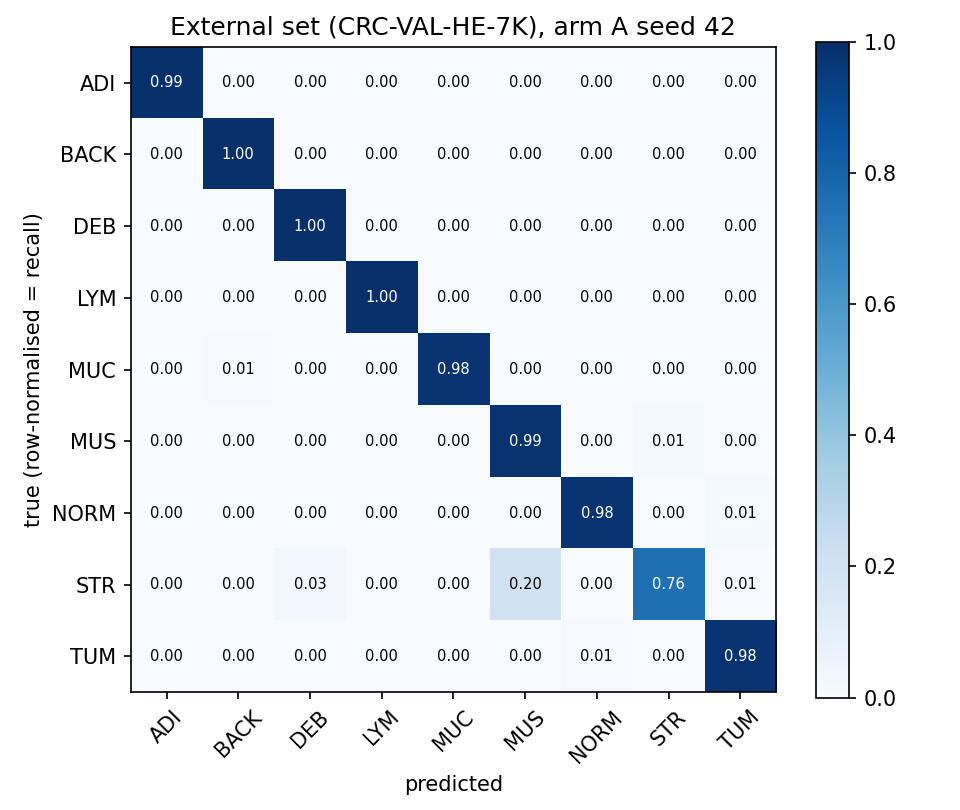

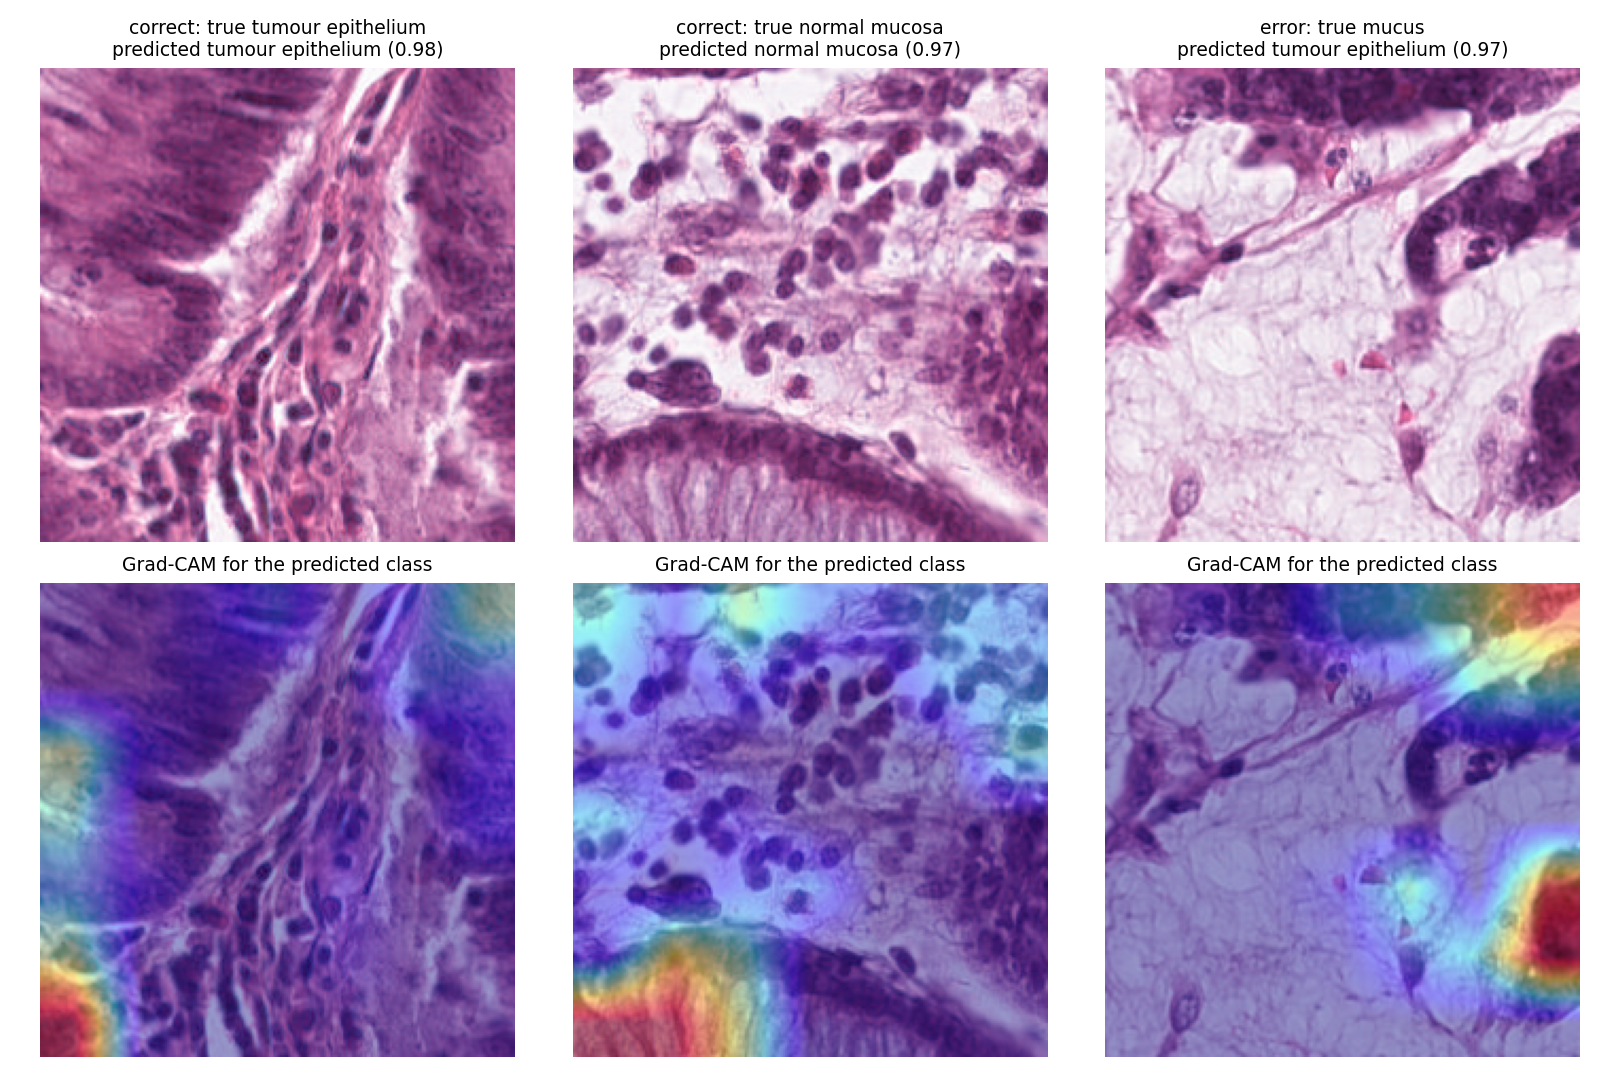

In [8]:
%cd /content/MedTech-Suite/day-4-crc-histopathology
import json
from IPython.display import Image, display
print(open('results/summary.json').read()[:3500])
print(open('results/leakage.json').read())
for f in ('confusion_external','gradcam_external'): display(Image(f'results/{f}.png'))